Q1(a) Load, inspect and report class distribution

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


In [ ]:
# Load the dataset
iris = pd.read_csv("/content/drive/MyDrive/DTU/AIML/LAB/datasets/iris.csv")

In [ ]:
print(iris.head())
print(iris.columns)

   sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa
Index(['sepal.length', 'sepal.width', 'petal.length', 'petal.width',
       'variety'],
      dtype='object')


In [ ]:

print(iris.info())
print(iris.describe())

print(iris["variety"].value_counts())

X = iris.drop("variety", axis=1)
y = iris["variety"]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
       sepal.length  sepal.width  petal.length  petal.width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.50000

In [ ]:

print("Class Distribution:")
print(iris["variety"].value_counts())

X = iris.drop("variety", axis=1)
y = iris["variety"]

print("Features:", X.columns.tolist())
print("Target: variety")


Class Distribution:
variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64
Features: ['sepal.length', 'sepal.width', 'petal.length', 'petal.width']
Target: variety


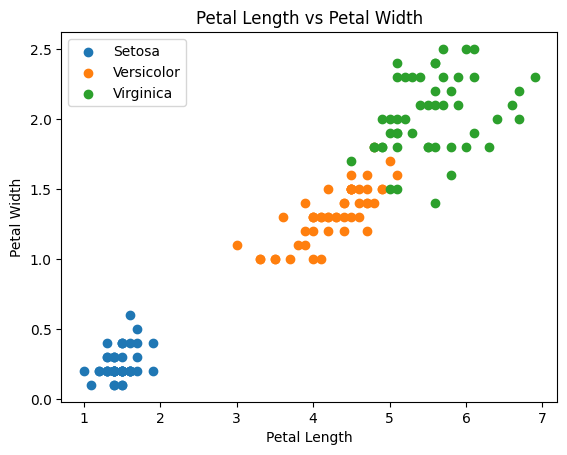

In [ ]:
for species in iris["variety"].unique():
    data = iris[iris["variety"] == species]
    plt.scatter(data["petal.length"], data["petal.width"], label=species)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Petal Length vs Petal Width")
plt.legend()
plt.show()


# **using k = 5 value**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10
   Virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
# Select one test sample
sample = X_test.iloc[[0]]

# Find 5 nearest neighbours
distances, indices = knn.kneighbors(sample)

print("Test sample:")
print(sample)

print("\nNearest neighbours:")
print(X_train.iloc[indices[0]])

print("\nDistances:")
print(distances[0])

print("\nNeighbour classes:")
print(y_train.iloc[indices[0]].values)

# Prediction and probabilities
print("\nPredicted class:", knn.predict(sample)[0])
print("Class probabilities:", knn.predict_proba(sample)[0])
print("Class order:", knn.classes_)


Test sample:
    sepal.length  sepal.width  petal.length  petal.width
38           4.4          3.0           1.3          0.2

Nearest neighbours:
    sepal.length  sepal.width  petal.length  petal.width
8            4.4          2.9           1.4          0.2
13           4.3          3.0           1.1          0.1
3            4.6          3.1           1.5          0.2
47           4.6          3.2           1.4          0.2
2            4.7          3.2           1.3          0.2

Distances:
[0.14142136 0.24494897 0.3        0.3        0.36055513]

Neighbour classes:
['Setosa' 'Setosa' 'Setosa' 'Setosa' 'Setosa']

Predicted class: Setosa
Class probabilities: [1. 0. 0.]
Class order: ['Setosa' 'Versicolor' 'Virginica']


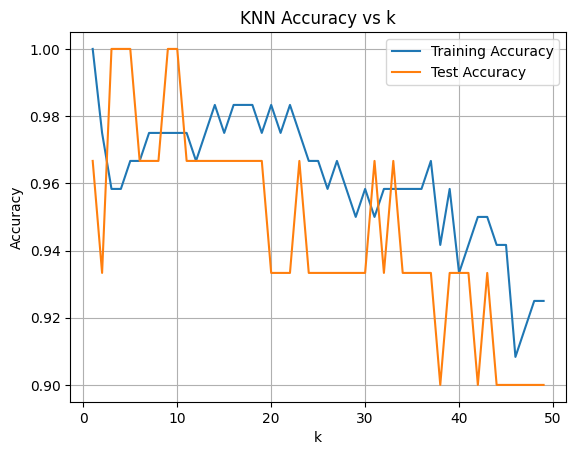

In [ ]:
train_acc = []
test_acc = []
k_values = range(1, 50, 1)

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.plot(k_values, train_acc, label="Training Accuracy")
plt.plot(k_values, test_acc, label="Test Accuracy")

plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs k")
plt.legend()
plt.grid()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 50, 1)
cv_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train, y_train, cv=5)
    cv_scores.append(scores.mean())

best_k = list(k_values)[cv_scores.index(max(cv_scores))]

print("Best k:", best_k)
print(cv_scores)
print("Best Cross-Validation Accuracy:", max(cv_scores))

Best k: 6
[np.float64(0.9416666666666668), np.float64(0.9583333333333333), np.float64(0.9583333333333334), np.float64(0.9666666666666668), np.float64(0.975), np.float64(0.9833333333333334), np.float64(0.975), np.float64(0.9666666666666666), np.float64(0.9583333333333334), np.float64(0.9583333333333334), np.float64(0.9583333333333334), np.float64(0.9666666666666666), np.float64(0.9583333333333334), np.float64(0.9666666666666668), np.float64(0.9666666666666666), np.float64(0.9583333333333334), np.float64(0.9666666666666666), np.float64(0.975), np.float64(0.9666666666666666), np.float64(0.9666666666666668), np.float64(0.9666666666666668), np.float64(0.95), np.float64(0.95), np.float64(0.9583333333333334), np.float64(0.9583333333333334), np.float64(0.9583333333333334), np.float64(0.9666666666666666), np.float64(0.95), np.float64(0.9666666666666666), np.float64(0.9416666666666667), np.float64(0.95), np.float64(0.9416666666666668), np.float64(0.9333333333333333), np.float64(0.908333333333333

5 fold verification result gave k = 6 value as the best as its cross validification score is the highest.


In [ ]:
# Test the selected model
best_model = KNeighborsClassifier(n_neighbors=best_k)
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))

Test accuracy: 0.9666666666666667


In [ ]:
for k, score in zip(k_values, cv_scores):
    print("k =", k, "CV Accuracy =", round(score, 3))

k = 1 CV Accuracy = 0.942
k = 2 CV Accuracy = 0.958
k = 3 CV Accuracy = 0.958
k = 4 CV Accuracy = 0.967
k = 5 CV Accuracy = 0.975
k = 6 CV Accuracy = 0.983
k = 7 CV Accuracy = 0.975
k = 8 CV Accuracy = 0.967
k = 9 CV Accuracy = 0.958
k = 10 CV Accuracy = 0.958
k = 11 CV Accuracy = 0.958
k = 12 CV Accuracy = 0.967
k = 13 CV Accuracy = 0.958
k = 14 CV Accuracy = 0.967
k = 15 CV Accuracy = 0.967
k = 16 CV Accuracy = 0.958
k = 17 CV Accuracy = 0.967
k = 18 CV Accuracy = 0.975
k = 19 CV Accuracy = 0.967
k = 20 CV Accuracy = 0.967
k = 21 CV Accuracy = 0.967
k = 22 CV Accuracy = 0.95
k = 23 CV Accuracy = 0.95
k = 24 CV Accuracy = 0.958
k = 25 CV Accuracy = 0.958
k = 26 CV Accuracy = 0.958
k = 27 CV Accuracy = 0.967
k = 28 CV Accuracy = 0.95
k = 29 CV Accuracy = 0.967
k = 30 CV Accuracy = 0.942
k = 31 CV Accuracy = 0.95
k = 32 CV Accuracy = 0.942
k = 33 CV Accuracy = 0.933
k = 34 CV Accuracy = 0.908
k = 35 CV Accuracy = 0.942
k = 36 CV Accuracy = 0.933
k = 37 CV Accuracy = 0.933
k = 38 CV Accu

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


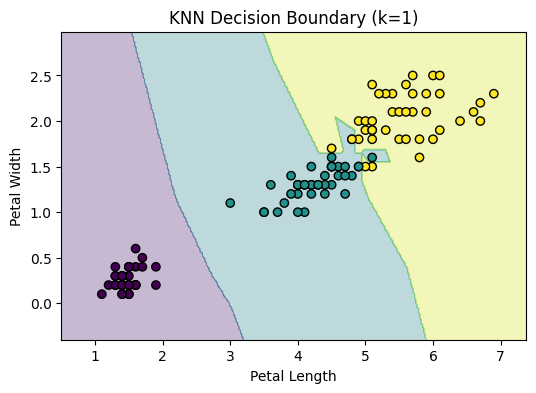

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


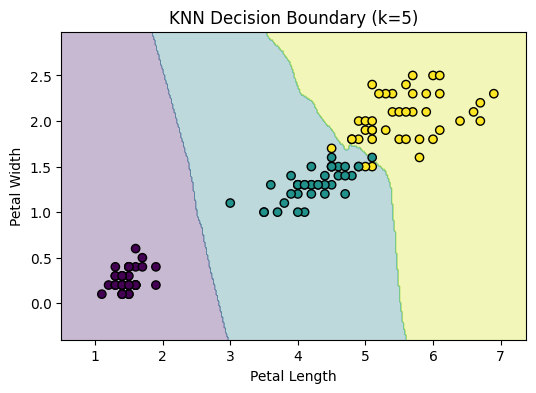

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


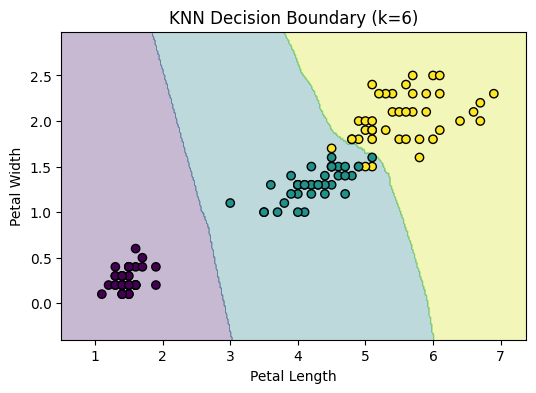

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


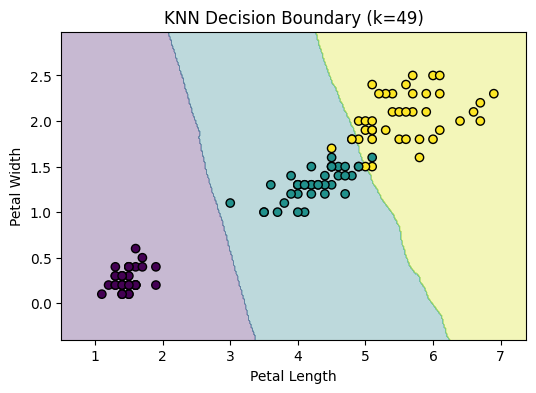

In [ ]:
X_two = iris[["petal.length", "petal.width"]]
y_two = iris["variety"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_two, y_two, test_size=0.2, random_state=42, stratify=y_two
)

k_values = [1, 5,6, 49]

x_min = X_two["petal.length"].min() - 0.5
x_max = X_two["petal.length"].max() + 0.5
y_min = X_two["petal.width"].min() - 0.5
y_max = X_two["petal.width"].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train2, y_train2)

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    # Convert class labels to numbers for plotting
    Z_num = np.zeros(Z.shape)
    for i, label in enumerate(model.classes_):
        Z_num[Z == label] = i

    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, Z_num, alpha=0.3)

    plt.scatter(
        X_train2["petal.length"],
        X_train2["petal.width"],
        c=y_train2.astype("category").cat.codes,
        edgecolors="black"
    )

    plt.xlabel("Petal Length")
    plt.ylabel("Petal Width")
    plt.title(f"KNN Decision Boundary (k={k})")
    plt.show()


# Q2

In [ ]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
wine_df = wine.data

print("First 5 rows:")
print(wine_df.head())

print("\nFeature Statistics:")
print(wine_df.agg(["min", "max", "mean"]).T)


First 5 rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0    

In [ ]:
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# KNN without scaling
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
pred_raw = knn_raw.predict(X_test)

print("Accuracy without scaling:", accuracy_score(y_test, pred_raw))

# KNN with StandardScaler
knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_scaled.fit(X_train, y_train)
pred_scaled = knn_scaled.predict(X_test)

print("Accuracy with scaling:", accuracy_score(y_test, pred_scaled))


Accuracy without scaling: 0.8055555555555556
Accuracy with scaling: 0.9722222222222222


In [ ]:
# StandardScaler
standard_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

standard_scores = cross_val_score(
    standard_model, X_train, y_train, cv=5
)

# MinMaxScaler
minmax_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

minmax_scores = cross_val_score(
    minmax_model, X_train, y_train, cv=5
)

print("StandardScaler CV Accuracy:", standard_scores.mean())
print("MinMaxScaler CV Accuracy:", minmax_scores.mean())


StandardScaler CV Accuracy: 0.9650246305418719
MinMaxScaler CV Accuracy: 0.9578817733990148


In [ ]:
# Create pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Values to test
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

# Find the best combination
grid = GridSearchCV(pipeline, param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

# Evaluate on test data
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)


print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:", confusion_matrix(y_test, y_pred))
print("\nClassification Report:", classification_report(y_test, y_pred))

Best Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 9, 'knn__weights': 'uniform'}
Best CV Accuracy: 0.9862068965517242
Test Accuracy: 1.0

Confusion Matrix: [[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [ ]:
np.random.seed(42)

noise_counts = [0, 10, 50, 200]

for n in noise_counts:
    # Add random noise features
    noise = np.random.randn(len(X_train), n)
    X_noise = np.hstack([X_train, noise])

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ])

    scores = cross_val_score(model, X_noise, y_train, cv=5)

    print("Noise features:", n)
    print("CV Accuracy:", scores.mean())
    print()


Noise features: 0
CV Accuracy: 0.9650246305418719

Noise features: 10
CV Accuracy: 0.9647783251231526

Noise features: 50
CV Accuracy: 0.8672413793103448

Noise features: 200
CV Accuracy: 0.7108374384236453



In [ ]:

# KNN
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

start = time.time()
knn.fit(X_train, y_train)
knn_train_time = time.time() - start

start = time.time()
knn_pred = knn.predict(X_test)
knn_predict_time = time.time() - start

# Logistic Regression
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

start = time.time()
lr.fit(X_train, y_train)
lr_train_time = time.time() - start

start = time.time()
lr_pred = lr.predict(X_test)
lr_predict_time = time.time() - start

print("KNN Training Time:", knn_train_time)
print("KNN Prediction Time:", knn_predict_time)
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

print("\nLogistic Regression Training Time:", lr_train_time)
print("Logistic Regression Prediction Time:", lr_predict_time)
print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))


KNN Training Time: 0.00774693489074707
KNN Prediction Time: 0.005647897720336914
KNN Accuracy: 0.9722222222222222

Logistic Regression Training Time: 0.00997614860534668
Logistic Regression Prediction Time: 0.0029435157775878906
Logistic Regression Accuracy: 0.9722222222222222


### When to Choose KNN Over Logistic Regression

KNN is useful when the dataset has complex decision boundaries and similar samples tend to belong to the same class. It is simple to implement and requires little training time. However, KNN is sensitive to feature scales, so scaling is important for datasets such as Wine. It can also become slow during prediction on large datasets because it calculates distances to stored training samples. Logistic Regression is generally preferable when fast predictions, lower memory usage, and an interpretable model are important. The choice between these algorithms should be based on cross-validation accuracy, test performance, and computational time.